NAME: MANASVI TOTEWAR (VLSI 15)

Machine Learning-Based Semiconductor Wafer Defect Classification.

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
import os

os.listdir('/content/drive/MyDrive/archive')

[]

In [7]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower().endswith('.zip') or file.lower().endswith('.pkl'):
            print(os.path.join(root, file))

/content/drive/MyDrive/Drift-Sense.zip
/content/drive/MyDrive/archive.zip


In [8]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/archive.zip'
extract_path = '/content/drive/MyDrive/archive'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path)[:20])

Extraction completed!
['LSWMD.pkl']


In [11]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive/archive'):
    for file in files:
        if file.lower().endswith('.pkl'):
            print(os.path.join(root, file))

/content/drive/MyDrive/archive/LSWMD.pkl


In [25]:
import pandas as pd
import numpy as np

# Load the dataset
file_path = '/content/drive/MyDrive/archive/LSWMD.pkl'
df = pd.read_pickle(file_path)

# Display confirmation
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display column names
print("Column names:", df.columns.tolist())

# Display the first 5 rows
display(df.head())

Dataset loaded successfully!
Dataset shape: (811457, 6)
Column names: ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [5]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive/archive'):
    for file in files:
        if file.endswith('.pkl'):
            print(os.path.join(root, file))

/content/drive/MyDrive/archive/LSWMD.pkl


In [6]:
import pandas as pd
import numpy as np

file_path = '/content/drive/MyDrive/archive/LSWMD.pkl'
df = pd.read_pickle(file_path)

print("Dataset loaded:", df.shape)

Dataset loaded: (811457, 6)


In [7]:
print(df['failureType'].head(10).tolist())

[array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4')]


In [8]:
print(df['waferMap'].iloc[0].shape)

(45, 48)


In [9]:
print(df['failureType'].iloc[:5000].value_counts())

failureType
[[none]]        4275
[[Edge-Loc]]      67
[[Loc]]           35
[[Random]]        19
[[Scratch]]       15
                ... 
[]                 1
[]                 1
[]                 1
[]                 1
[]                 1
Name: count, Length: 577, dtype: int64


In [10]:
import numpy as np
import pandas as pd

def clean_label(value):
    while isinstance(value, (list, tuple, np.ndarray)):
        if len(value) == 0:
            return None
        value = value[0]

    if pd.isna(value):
        return None

    return str(value).strip()

df['label'] = df['failureType'].apply(clean_label)

print(df['label'].iloc[:5000].value_counts())

label
none         4275
Edge-Loc       67
Loc            35
Random         19
Scratch        15
Center          9
Near-full       6
Edge-Ring       5
Name: count, dtype: int64


In [11]:
print(df['label'].value_counts().head(15))

label
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [12]:
selected_classes = [
    'Center',
    'Edge-Loc',
    'Edge-Ring',
    'Scratch'
]

sample_size = 500

parts = []

for category in selected_classes:
    subset = df[df['label'] == category]

    n = min(sample_size, len(subset))

    parts.append(
        subset.sample(n=n, random_state=42)
    )

data = pd.concat(parts, ignore_index=True)

print("Selected dataset size:", len(data))
print(data['label'].value_counts())

Selected dataset size: 2000
label
Center       500
Edge-Loc     500
Edge-Ring    500
Scratch      500
Name: count, dtype: int64


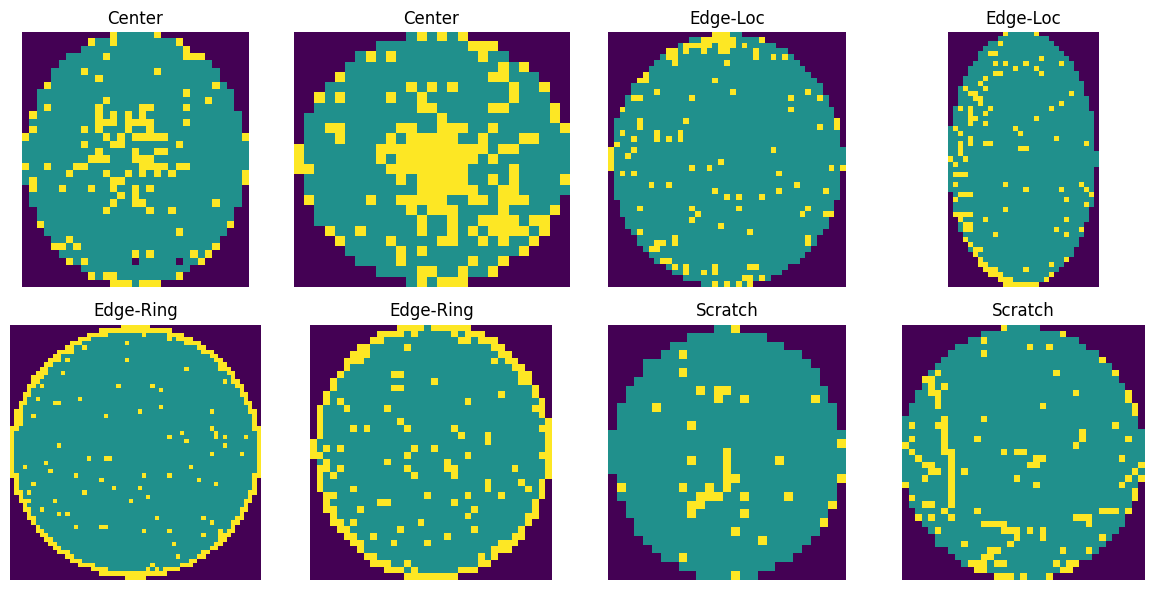

In [13]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flat, data.groupby('label').head(2).iterrows()):
    wafer = np.asarray(row['waferMap'])

    ax.imshow(wafer, cmap='viridis', interpolation='nearest')
    ax.set_title(row['label'])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [14]:
import tensorflow as tf

images = []
labels = []

for _, row in data.iterrows():
    wafer = np.asarray(row['waferMap'])

    if wafer.ndim != 2 or wafer.size == 0:
        continue

    wafer = tf.image.resize(
        wafer[..., np.newaxis].astype('float32'),
        (32, 32),
        method='nearest'
    ).numpy()

    images.append(wafer)
    labels.append(row['label'])

X = np.array(images, dtype='float32') / 2.0

label_to_number = {
    label: index
    for index, label in enumerate(selected_classes)
}

y = np.array([label_to_number[label] for label in labels])

print("Image array shape:", X.shape)
print("Label array shape:", y.shape)

Image array shape: (2000, 32, 32, 1)
Label array shape: (2000,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (1600, 32, 32, 1)
Testing images: (400, 32, 32, 1)


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([
    Input(shape=(32, 32, 1)),

    Conv2D(16, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,852 (308.02 KB)

 Trainable params: 78,852 (308.02 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
history = model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 90ms/step - accuracy: 0.3414 - loss: 1.3522 - val_accuracy: 0.6531 - val_loss: 1.2795
Epoch 2/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 124ms/step - accuracy: 0.5281 - loss: 1.1694 - val_accuracy: 0.6562 - val_loss: 1.0004
Epoch 3/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 123ms/step - accuracy: 0.6172 - loss: 0.9213 - val_accuracy: 0.6469 - val_loss: 0.7749
Epoch 4/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.6609 - loss: 0.7888 - val_accuracy: 0.7531 - val_loss: 0.6443
Epoch 5/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.6852 - loss: 0.7072 - val_accuracy: 0.7563 - val_loss: 0.6019
Epoch 6/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7336 - loss: 0.6406 - val_accuracy: 0.7719 - val_loss: 0.5588
Epoch 7/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7383 - loss: 0.5977 - val_accuracy: 0.7844 - val_loss: 0.5169
Epoch 8/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7461 - loss: 0.5882 - val_accuracy: 0.7688 - val_los

In [18]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 78.00%
Test Loss: 0.5191


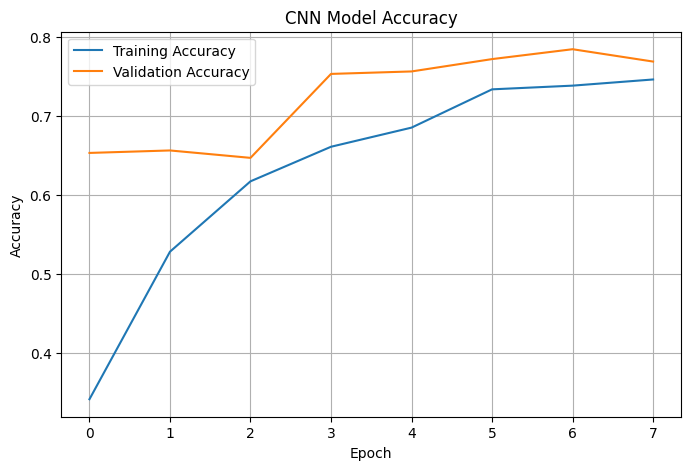

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Model Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [20]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 78.00%
Test Loss: 0.5191


In [21]:
from sklearn.metrics import classification_report

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=selected_classes,
    zero_division=0
))

              precision    recall  f1-score   support

      Center       0.92      0.98      0.95       100
    Edge-Loc       0.58      0.75      0.66       100
   Edge-Ring       0.84      0.91      0.88       100
     Scratch       0.86      0.48      0.62       100

    accuracy                           0.78       400
   macro avg       0.80      0.78      0.77       400
weighted avg       0.80      0.78      0.77       400



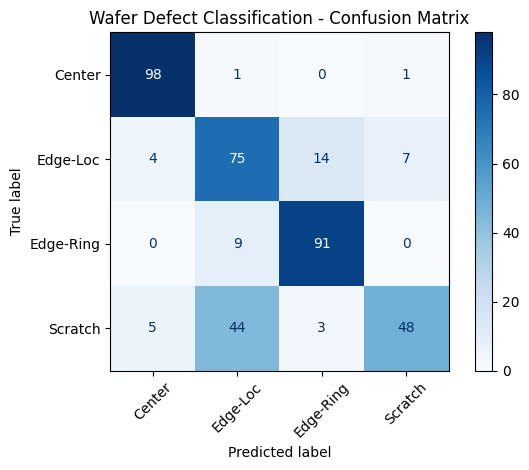

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=selected_classes
)

display_matrix.plot(cmap='Blues', xticks_rotation=45)
plt.title("Wafer Defect Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

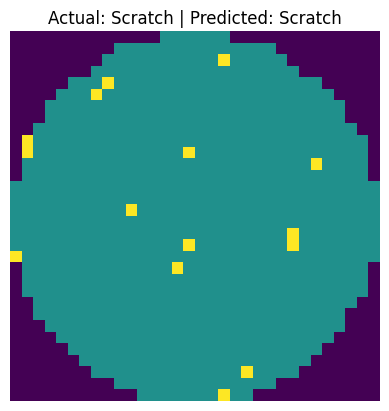

Actual defect: Scratch
Predicted defect: Scratch
Prediction confidence: 61.04%


In [23]:
i = 0

probabilities = model.predict(X_test[i:i+1], verbose=0)[0]

predicted_label = selected_classes[np.argmax(probabilities)]
actual_label = selected_classes[y_test[i]]

plt.imshow(X_test[i].squeeze(), cmap='viridis')
plt.title(f"Actual: {actual_label} | Predicted: {predicted_label}")
plt.axis('off')
plt.show()

print("Actual defect:", actual_label)
print("Predicted defect:", predicted_label)
print(f"Prediction confidence: {np.max(probabilities) * 100:.2f}%")

In [24]:
model.save(
    '/content/drive/MyDrive/archive/wafer_defect_model.keras'
)

print("Model saved successfully!")

Model saved successfully!
